# Adaptive Gaussian Pd/Qd sampling and Julia AC-OPF verification


## 1. Imports, state/grid selection and Julia verifier

In [ ]:
import copy
import csv
import hashlib
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from juliacall import Main as jl

In [61]:
DATASET_NAME = "alabama"    # Same as load notebook; use "texas" if preferred
TIME_SLICE = "16h"
DATA_DIR = Path("../power_grid/US/gridsfm_data") / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"
JULIA_SCRIPT = Path("../verifier/acopf_verifier.jl")
OUTPUT_DIR = Path("../results/gaussian_load_centered") / "results" / "gaussian_voltage_squeeze" / DATASET_NAME
SCENARIO_PATH = OUTPUT_DIR / "acopf_labeled_scenarios.npz"

DATASET_LABEL = DATASET_NAME.replace("_", " ").title()
assert DATA_PATH.is_file(), f"Grid case not found: {DATA_PATH}"
assert JULIA_SCRIPT.is_file(), f"Julia verifier not found: {JULIA_SCRIPT}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("bus"), dict), "Expected case with a 'bus' dictionary"
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_LABEL, "| Case:", DATA_PATH)
print("Julia verifier:", JULIA_SCRIPT)
print("Output directory:", OUTPUT_DIR)
print("Buses:", len(data["bus"]), "| baseMVA:", data.get("baseMVA"))

Dataset: Alabama | Case: ../power_grid/US/gridsfm_data/16h/alabama_model.json
Julia verifier: ../verifier/acopf_verifier.jl
Output directory: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama
Buses: 494 | baseMVA: 100.0


## 2. Preserve mapping between Python load rows and Julia load IDs

In [62]:
# Preserve load IDs so we can map samples back
load_ids = []
for load_id, load in data["load"].items():
    if load["status"] == 1:
        load_ids.append(load_id)

# Original load dataset: columns [Pd, Qd]
loads = []
for load_id in load_ids:
    loads.append([
        data["load"][load_id]["pd"],
        data["load"][load_id]["qd"]
    ])

loads = np.array(loads, dtype=float)
n_loads = len(load_ids)

assert n_loads >= 2, "This Gaussian covariance requires at least two active loads."
assert loads.shape == (n_loads, 2) and np.isfinite(loads).all()

print("Active loads:", n_loads, "| Shape:", loads.shape)
print("Original mean [Pd,Qd]:", loads.mean(axis=0), "| Base MVA:", data.get("baseMVA"))
print("Original total [Pd,Qd] (p.u.):", loads.sum(axis=0), "| Base MVA:", data.get("baseMVA"))


Active loads: 494 | Shape: (494, 2)
Original mean [Pd,Qd]: [0.19233127 0.08193278] | Base MVA: 100.0
Original total [Pd,Qd] (p.u.): [95.011645   40.47479128] | Base MVA: 100.0


## 3. Initialize the existing PowerModels AC-OPF verifier for this case


In [63]:
jl.include(str(JULIA_SCRIPT.resolve()))
summary_text = jl.GridSFMLoadVerifier.initialize_case(
    str(DATA_PATH.resolve()), json.dumps(load_ids)
)
print("Julia case initialized:\n", json.loads(str(summary_text)))


Julia case initialized:
 {'n_buses': 494, 'baseMVA': 100.0, 'supported_modes': ['branch', 'bus', 'gen', 'load'], 'initialized': True, 'n_loads': 494, 'n_generators': 55, 'n_total_loads': 494, 'n_branches': 864, 'per_unit': True}


## 4. Python wrapper and baseline AC-OPF check


In [ ]:
def verify_scenario(patch):
    start = time.perf_counter()
    try:
        if not isinstance(patch, dict) or not patch:
            raise ValueError("patch must be a nonempty dictionary")
        raw = jl.GridSFMLoadVerifier.verify_scenario_json(
            json.dumps(patch, allow_nan=False)
        )
        result = json.loads(str(raw))
        result["elapsed_s"] = time.perf_counter() - start
        return result
    except Exception as exc:
        return {
            "accepted": False, "status": "CALL_ERROR", "objective": None,
            "reason": str(exc)[:1000], "termination_status": "ERROR",
            "primal_status": "UNKNOWN", "elapsed_s": time.perf_counter() - start,
        }


def build_load_patch(candidate_loads):
    values = np.asarray(candidate_loads, dtype=float)
    if values.shape != loads.shape or not np.isfinite(values).all():
        raise ValueError(f"Expected finite shape {loads.shape}, got {values.shape}")
    return {"load": {
        str(load_id): {"pd": float(pair[0]), "qd": float(pair[1])}
        for load_id, pair in zip(load_ids, values)
    }}


def verify_acopf(candidate_loads):
    start = time.perf_counter()
    try:
        patch = build_load_patch(candidate_loads)
    except (ValueError, TypeError) as exc:
        return {
            "accepted": False, "status": "INVALID_INPUT", "objective": None,
            "reason": str(exc), "termination_status": "NOT_RUN",
            "primal_status": "UNKNOWN", "elapsed_s": time.perf_counter() - start,
        }
    return verify_scenario(patch)

In [65]:
print(f"Verifying the original {DATASET_LABEL} case")
baseline_result = verify_acopf(loads)
print("Baseline:\n", baseline_result)
if not baseline_result["accepted"]:
    raise RuntimeError("Baseline not confirmed: " + str(baseline_result))

Verifying the original Alabama case
Baseline:
 {'stage': 'validation', 'modes': [], 'termination_status': 'NOT_RUN', 'objective': None, 'primal_status': 'UNKNOWN', 'reason': 'Scenario must be a JSON object with load/branch/gen/bus sections', 'warnings': [], 'applied_components': {}, 'solve_time': None, 'accepted': False, 'status': 'INVALID_SCENARIO', 'elapsed_s': 0.1317704590037465}


RuntimeError: Baseline not confirmed: {'stage': 'validation', 'modes': [], 'termination_status': 'NOT_RUN', 'objective': None, 'primal_status': 'UNKNOWN', 'reason': 'Scenario must be a JSON object with load/branch/gen/bus sections', 'warnings': [], 'applied_components': {}, 'solve_time': None, 'accepted': False, 'status': 'INVALID_SCENARIO', 'elapsed_s': 0.1317704590037465}

## 5. Gaussian Initialization


In [ ]:
SEED = 42
iterations = 10             
samples_per_iteration =2    # Each costs one large Julia AC-OPF solve
alpha = 0.30                # Accepted-only exponential smoothing

scale_rng = np.random.default_rng(SEED + 1) 
INITIAL_SCALE = scale_rng.uniform(1.0, 1.8) # Earlier experiments had mixed acceptance at this scale => Controls initial perturbation magnitude
NONNEGATIVE = True          # Enforce nonnegative Pd and Qd through pair rejection
MAX_RESAMPLE_ROUNDS = 100   # Avoids resampling indefinitely
COV_REG = 1e-10             # Numerical stability => Adds a tiny diagonal value for numerical stability

rng = np.random.default_rng(SEED)
base_cov = np.cov(loads, rowvar=False, bias=True)
base_cov = 0.5 * (base_cov + base_cov.T) # Computers use floating-point arithmetic, which sometimes produces tiny numerical differences. Mathematically, the two off-diagonal values should be identical, but here they differ slightly. So, this ensures the covariance matrix is symmetric

# Initially: Generate random perturbations around the original loads.  
# After verification: Use accepted noise values to update the mean and covariance.
noise_mu = np.zeros(2) # this is to randomize noise around 0 so the perturbation is centered around the original load values not too far away from the original load values
noise_cov = (INITIAL_SCALE ** 2) * base_cov + np.eye(2) * COV_REG
initial_noise_mu = noise_mu.copy()
initial_noise_cov = noise_cov.copy()

history = [] # Track Gaussian learning Mean, standard deviation, covariance, acceptance rate for each iteration
verification_log = [] # Record AC-OPF results & Verification results for every scenario
explain_candidates = [] # Save scenarios for explainability All proposed load matrices, accepted and rejected
explain_labels = [] # Store acceptance labels 1 for accepted, 0 for not accepted
explain_metadata = [] # Store scenario information Iteration, scenario number, solver status
last_proposed = None # Remember latest generated samples & All scenarios from the last iteration
last_applied = None # Remember latest accepted samples & Accepted scenarios from the last iteration

print("Original data covariance:\n", base_cov)
print("Initial noise mean:", noise_mu)
print("Initial noise std:", np.sqrt(np.diag(noise_cov)))
print("Total proposed scenarios:", iterations * samples_per_iteration)


Original data covariance:
 [[0.00635228 0.00270606]
 [0.00270606 0.00115278]]
Initial noise mean: [0. 0.]
Initial noise std: [0.03985061 0.01697629]
Total proposed scenarios: 20


## 7. Load-centered Gaussian sampler with optional nonnegative pair rejection

In [ ]:
def sample_load_centered_gaussian(rng, loads, noise_mu, noise_cov,
                                  n_scenarios, nonnegative=True,
                                  max_rounds=1000):
    """Return proposed absolute loads, realized noise, and draw diagnostics."""
    n = len(loads)
    noise = rng.multivariate_normal(noise_mu, noise_cov, size=(n_scenarios, n),
                                    check_valid="raise")
    candidates = loads[None, :, :] + noise
    initial_invalid = int(np.any(candidates < 0, axis=-1).sum()) # count how many load pairs have negative Pd or Qd values immediately after the first Gaussian sampling, before any resampling happens
    rounds, total_redraws = 0, 0
    if nonnegative:
        invalid = np.any(candidates < 0, axis=-1) # identify indexes which individual load pairs contain negative values so we can redraw only those pairs
        while invalid.any() and rounds < max_rounds:
            count = int(invalid.sum())
            noise[invalid] = rng.multivariate_normal(noise_mu, noise_cov, size=count,
                                                      check_valid="raise") # Replace only invalid pairs
            candidates = loads[None, :, :] + noise
            total_redraws += count
            rounds += 1
            invalid = np.any(candidates < 0, axis=-1)
        if invalid.any():
            raise RuntimeError(f"Failed to draw nonnegative load pairs for {invalid.sum()} "
                               f"positions in {max_rounds} rounds; consider a smaller scale")
    assert np.isfinite(candidates).all()
    if nonnegative:
        assert np.all(candidates >= 0)
    return candidates, noise, {
        "total_pairs": int(n_scenarios * n),
        "initial_invalid_pairs": initial_invalid,
        "resampling_rounds": rounds,
        "redrawn_pairs_total": total_redraws,
        "negative_pd_after": int((candidates[..., 0] < 0).sum()),
        "negative_qd_after": int((candidates[..., 1] < 0).sum()),
    }

## 8. Adaptive loop — sampling, unchanged verifier, accepted-noise update


In [ ]:
# Generates scenarios, verifies them, and updates the Gaussian distribution.
for iteration in range(iterations):
    # sampling_diag is a dictionary of system diagnostics that contains information about the sampling process, such as the total number of pairs, the number of initial invalid pairs, the number of resampling rounds, and the number of redrawn pairs.
    sampled, sampled_noise, sampling_diag = sample_load_centered_gaussian(
        rng, loads, noise_mu, noise_cov,
        n_scenarios=samples_per_iteration,
        nonnegative=NONNEGATIVE,
        max_rounds=MAX_RESAMPLE_ROUNDS,
    )
    good_samples_list = []
    good_noise_list = []
    print(f"\nIteration {iteration + 1}: resampled "
          f"{sampling_diag['initial_invalid_pairs']}/{sampling_diag['total_pairs']} "
          f"initial invalid pairs in {sampling_diag['resampling_rounds']} rounds", flush=True)

    # Checks each generated scenario individually using Julia AC-OPF.
    for scenario_idx in range(samples_per_iteration):
        candidate_loads = sampled[scenario_idx]
        verification = verify_acopf(candidate_loads)
        deviation = np.abs(candidate_loads - loads) # calculates changes for individual loads
        total_change_pct = 100.0 * (candidate_loads.sum(axis=0) / loads.sum(axis=0) - 1) # calculates changes in the aggregate grid demand
        row = {
            "iteration": iteration + 1,
            "scenario": scenario_idx + 1,
            "pd_change_pct": float(total_change_pct[0]),
            "qd_change_pct": float(total_change_pct[1]),
            "mean_abs_pd_change": float(deviation[:, 0].mean()),
            "mean_abs_qd_change": float(deviation[:, 1].mean()),
            "negative_pd": int((candidate_loads[:, 0] < 0).sum()),
            "negative_qd": int((candidate_loads[:, 1] < 0).sum()),
            **verification,
        }
        verification_log.append(row)
        # Save ALL proposed scenarios (including rejected); Julia labels are for comparison only.
        explain_candidates.append(candidate_loads.astype(np.float32).copy()) # Entire load matrix
        explain_labels.append(int(verification["accepted"])) # Store acceptance labels 1 for accepted, 0 for not accepted
        explain_metadata.append((iteration + 1, scenario_idx + 1,
                                 verification["status"],
                                 verification.get("termination_status", ""))) # Identify the scenario and solver result
        print(f"{iteration + 1}/{iterations}, scenario "
              f"{scenario_idx + 1}/{samples_per_iteration}: "
              f"{verification['status']} ({verification.get('termination_status')}, "
              f"{verification['elapsed_s']:.1f}s), "
              f"total Pd change={total_change_pct[0]:+.8f}%,"
               f"total Qd change={total_change_pct[1]:+.8f}%", flush=True)
        if verification.get("reason"):
            print("     Reason:", verification["reason"][:350], flush=True)

        if verification["accepted"]:
            good_samples_list.append(candidate_loads.copy())
            good_noise_list.append(sampled_noise[scenario_idx].copy()) # Save the noise that produced the accepted load scenario

    accepted_count = len(good_samples_list)
    good_sampled = (np.stack(good_samples_list)
                    if accepted_count 
                    else np.empty((0, n_loads, 2), dtype=float))

    if accepted_count:
        accepted_noise = np.stack(good_noise_list).reshape(-1, 2)
        new_mu = accepted_noise.mean(axis=0)
        new_cov = np.cov(accepted_noise, rowvar=False, bias=True)
        noise_mu = (1.0 - alpha) * noise_mu + alpha * new_mu
        noise_cov = (1.0 - alpha) * noise_cov + alpha * new_cov
        noise_cov = 0.5 * (noise_cov + noise_cov.T) + np.eye(2) * COV_REG

    history.append({
        "iteration": iteration + 1,
        "noise_mu": noise_mu.copy(),
        "noise_std": np.sqrt(np.diag(noise_cov)).copy(),
        "noise_cov": noise_cov.copy(),
        "accepted_count": accepted_count,
        "rejected_count": samples_per_iteration - accepted_count,
        "acceptance_rate": accepted_count / samples_per_iteration,
        "updated": bool(accepted_count),
        **sampling_diag,
    })
    last_proposed = sampled.copy() # Remember latest generated samples & All scenarios from the last iteration
    last_applied = good_sampled.copy() # Remember latest accepted samples & Accepted scenarios from the last iteration
    # Save after each iteration, so an interrupted Narval session retains data.
    np.savez_compressed(
        SCENARIO_PATH,
        candidates=np.stack(explain_candidates),
        accepted=np.asarray(explain_labels, dtype=np.int64),
        load_ids=np.asarray(load_ids),
        dataset_name=np.asarray(DATASET_NAME),
        source_case_sha256=np.asarray(CASE_SHA256),
        source_case_path=np.asarray(str(DATA_PATH.resolve())),
        iteration=np.asarray([m[0] for m in explain_metadata]),
        scenario=np.asarray([m[1] for m in explain_metadata]),
        status=np.asarray([m[2] for m in explain_metadata]),
        termination_status=np.asarray([m[3] for m in explain_metadata]),
    )
    print(f"Iteration {iteration + 1}: accepted {accepted_count}/{samples_per_iteration}, "
          f"noise mean={np.round(noise_mu, 6)}, "
          f"noise std={np.round(np.sqrt(np.diag(noise_cov)), 6)}", flush=True)

print("\nFinal proposed:", last_proposed.shape if last_proposed is not None else None)
print("Final accepted:", last_applied.shape if last_applied is not None else None)
print("Overall accepted:", sum(h['accepted_count'] for h in history),
      '/', iterations * samples_per_iteration)


Iteration 1: resampled 3/988 initial invalid pairs in 1 rounds
1/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.7s), total Pd change=+0.68999843%,total Qd change=+0.68937801%
1/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+2.52611358%,total Qd change=+2.52571393%
Iteration 1: accepted 2/2, noise mean=[0.000928 0.000395], noise std=[0.039719 0.01692 ]

Iteration 2: resampled 7/988 initial invalid pairs in 1 rounds
2/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+0.07134164%,total Qd change=+0.07125430%
2/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+0.89449832%,total Qd change=+0.89509898%
Iteration 2: accepted 2/2, noise mean=[0.000928 0.000395], noise std=[0.039539 0.016843]

Iteration 3: resampled 7/988 initial invalid pairs in 1 rounds
3/10, scenario 1/2: OPF_SOLVED (LOCALLY_SOLVED, 0.8s), total Pd change=+0.35524548%,total Qd change=+0.35417810%
3/10, scenario 2/2: OPF_SOLVED (LOCALLY_SOLVED, 0.7s), total Pd c

## 9. Visualize acceptance and adaptation

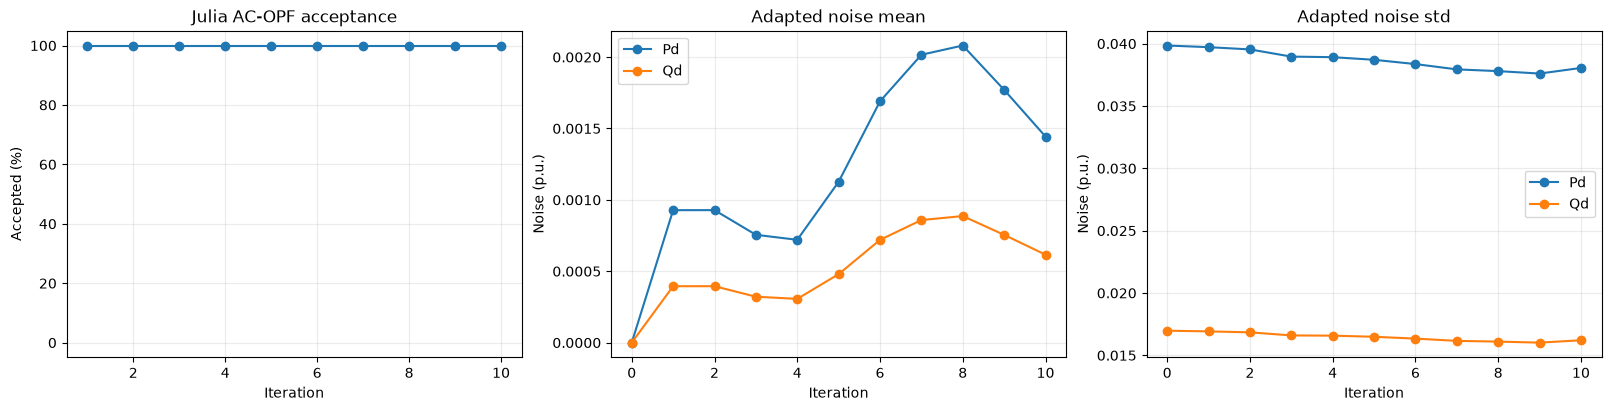

In [ ]:
if not history:
    print("No iterations to plot")
else:
    xs = [h["iteration"] for h in history]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
    axes[0].plot(xs, [100*h["acceptance_rate"] for h in history], marker="o")
    axes[0].set(title="Julia AC-OPF acceptance", xlabel="Iteration", ylabel="Accepted (%)", ylim=(-5, 105))
    for j, name in enumerate(["Pd", "Qd"]):
        axes[1].plot([0]+xs, [initial_noise_mu[j]]+[h["noise_mu"][j] for h in history],
                     marker="o", label=name)
        axes[2].plot([0]+xs, [np.sqrt(initial_noise_cov[j,j])]+[h["noise_std"][j] for h in history],
                     marker="o", label=name)
    axes[1].set(title="Adapted noise mean", xlabel="Iteration", ylabel="Noise (p.u.)")
    axes[2].set(title="Adapted noise std", xlabel="Iteration", ylabel="Noise (p.u.)")
    for ax in axes:
        ax.grid(alpha=0.25)
    axes[1].legend()
    axes[2].legend()
    plt.show()


## 10. Plot original, proposed, and accepted absolute loads

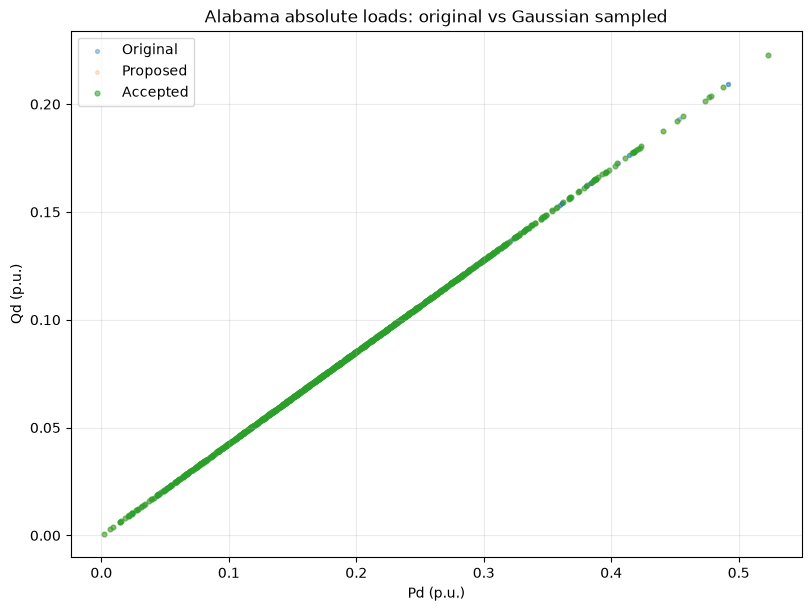

In [ ]:
viz_rng = np.random.default_rng(123)
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
for arr, label, size, transparency in [
    (loads, "Original", 8, 0.35),
    (last_proposed.reshape(-1, 2), "Proposed", 7, 0.2),
    (last_applied.reshape(-1, 2), "Accepted", 12, 0.55),
]:
    if len(arr) == 0:
        continue
    idx = viz_rng.choice(len(arr), size=min(3000, len(arr)), replace=False)
    pts = arr[idx]
    ax.scatter(pts[:,0], pts[:,1], s=size, alpha=transparency, label=label, rasterized=True)
ax.set(title=f"{DATASET_LABEL} absolute loads: original vs Gaussian sampled", xlabel="Pd (p.u.)", ylabel="Qd (p.u.)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 11. Export training logs

In [ ]:
log_path = OUTPUT_DIR / "verification_log.csv"
with log_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["iteration", "scenario", "accepted", "status", "termination_status",
            "primal_status", "objective", "solve_time", "elapsed_s", "reason",
            "pd_change_pct", "qd_change_pct", "mean_abs_pd_change",
            "mean_abs_qd_change", "negative_pd", "negative_qd"]
    writer = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(verification_log)

history_path = OUTPUT_DIR / "sampling_history.csv"
with history_path.open("w", newline="", encoding="utf-8") as f:
    cols = ["iteration", "accepted_count", "rejected_count", "acceptance_rate",
            "updated", "total_pairs", "initial_invalid_pairs", "resampling_rounds",
            "redrawn_pairs_total", "negative_pd_after", "negative_qd_after",
            "noise_mu_pd", "noise_mu_qd", "noise_std_pd", "noise_std_qd"]
    writer = csv.DictWriter(f, fieldnames=cols)
    writer.writeheader()
    for h in history:
        writer.writerow({**{k: h[k] for k in cols if k in h},
                         "noise_mu_pd": float(h["noise_mu"][0]),
                         "noise_mu_qd": float(h["noise_mu"][1]),
                         "noise_std_pd": float(h["noise_std"][0]),
                         "noise_std_qd": float(h["noise_std"][1])})

print("Verification log:", log_path)
print("History log:", history_path)

Accepted model: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/first_accepted_model.json (iteration/scenario: (1, 1) )
Verification log: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/verification_log.csv
History log: ../results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/sampling_history.csv
